In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from graphviz import Digraph

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

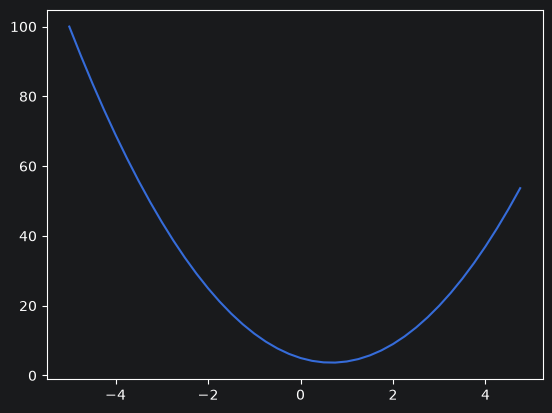

In [3]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [4]:
h = 0.0000001
x = 2/3
fx = (f(x+h) - f(x))/h
fx

2.9753977059954195e-07

In [5]:
a = 2.0
b = -3.0
c = 10.0
d = a * b + c
print(d)

4.0


In [6]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0
d1 = a * b + c

a += h
d2 = a * b + c

print("d1:", d1)
print("d2:", d2)
print("derivative(Slope):", (d2 - d1) / h)

d1: 4.0
d2: 3.999699999999999
derivative(Slope): -3.000000000010772


In [7]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._backward = lambda: None

    def __repr__(self) -> str:
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, _children=(self, other), _op='+')
        def _backward():
            self.grad = 1.0 * out.grad
            other.grad = 1.0 * out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, _children=(self, other), _op='*')
        def _backward():
            self.grad = other.data * out.grad
            other.grad = self.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2 * x) -1)/(math.exp(2 * x) + 1)
        out = Value(t, _children=(self,), _op='tanh')
        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        return out

In [8]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
d = a * b
d.label = 'd'
e = d + c
e.label = 'e'
f = Value(-2.0, label='f')
L = e * f
L.label = 'L'
print(a)
print(b)
print(c)
print(d)
print(e)
print(f)
print(L)
print(f)
L.grad = 1.0


Value(data=2.0)
Value(data=-3.0)
Value(data=10.0)
Value(data=-6.0)
Value(data=4.0)
Value(data=-2.0)
Value(data=-8.0)
Value(data=-2.0)


In [9]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(name=str(id(n)), label = "{%s| data %.4f| grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


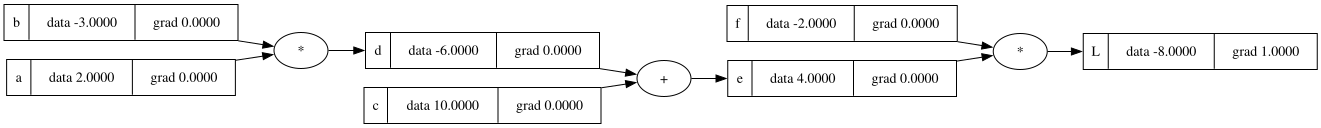

In [10]:
draw_dot(L)

In [11]:
L.grad  = 1.0

In [12]:
def lol():
    h = 0.001
    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    d = a * b; d.label = 'd'
    e = d + c; e.label = 'e'
    f = Value(-2.0, label='f')
    L = e * f; L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    d = a * b; d.label = 'd'
    e = d + c; e.label = 'e'
    f = Value(-2.0+h, label='f')
    L = e * f; L.label = 'L'
    L2 = L.data
    print((L1 - L2) / h)

lol()

-3.9999999999995595


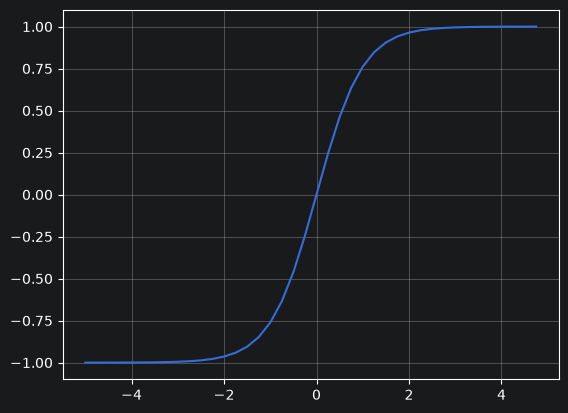

In [13]:
plt.plot(np.arange(-5, 5, 0.25), np.tanh(np.arange(-5, 5, 0.25)))
plt.grid()

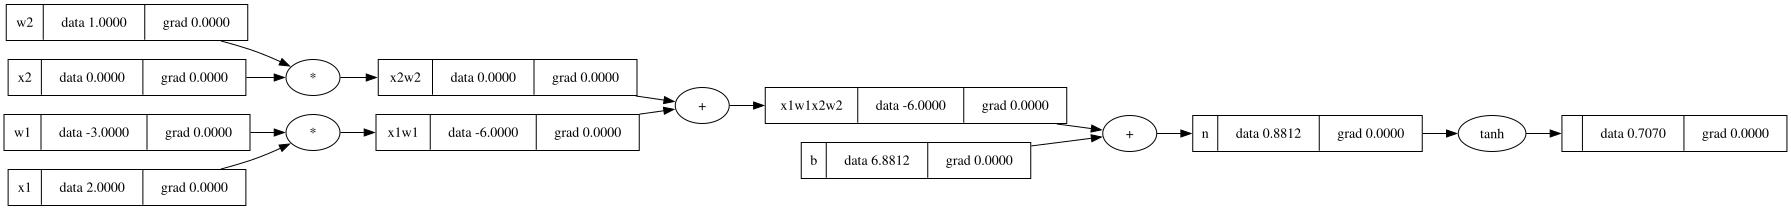

In [14]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.8812212, label='b')

x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'

n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh()
draw_dot(n)
draw_dot(o)

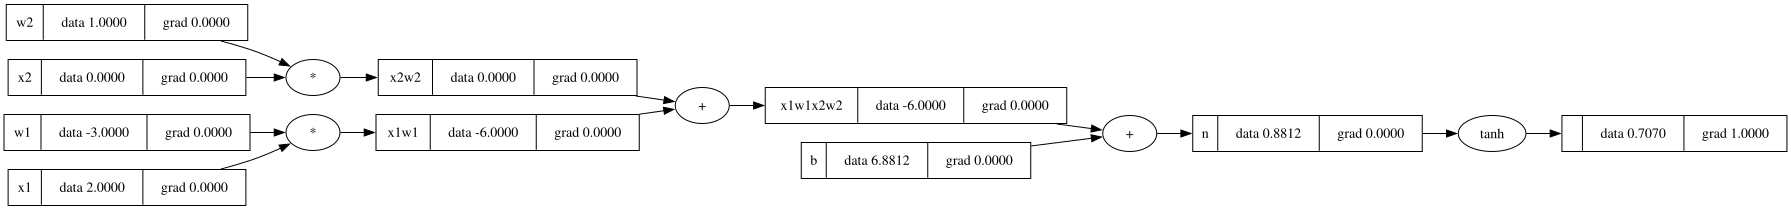

In [15]:
o.grad = 1.0
draw_dot(o)

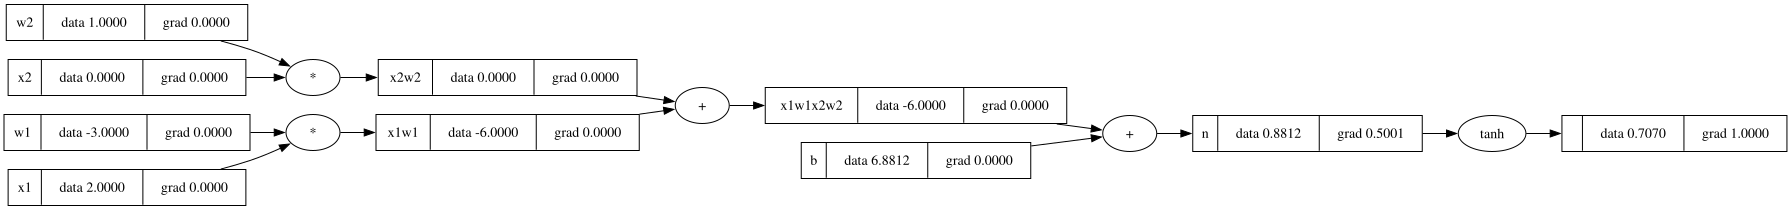

In [16]:
# o = tanh(n)
# do/dn = 1 - tanh(n)^2
#       = 1 - o^2
o._backward()
draw_dot(o)

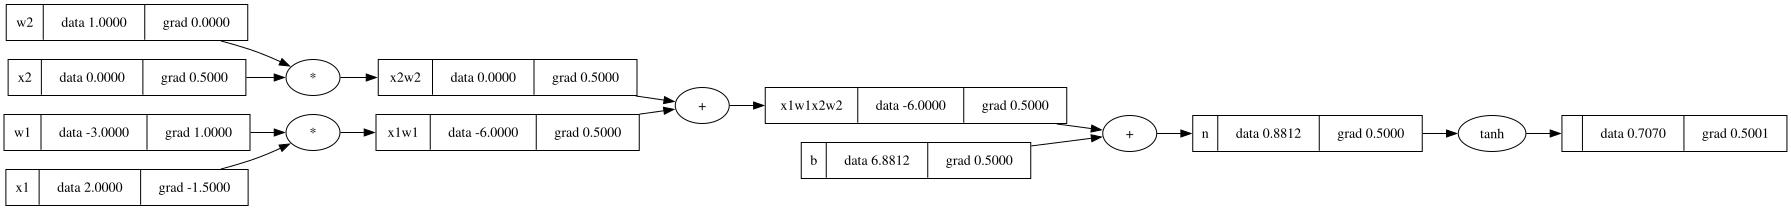

In [17]:

x1w1.grad = 0.5
x2w2.grad = 0.5
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad
x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

x1w1x2w2.grad = 0.5
b.grad = 0.5
n.grad = 0.5
o.grad = 1.0
o.grad *= 1 - o.data**2
draw_dot(o)
